Develop machine learning models to classify emotions in text samples.

In [1]:
import numpy as np

In [2]:
import pandas as pd

In [4]:
df = pd.read_csv('nlp_dataset.csv')

In [5]:
df.head()

,Comment,Emotion
0,i seriously hate one subject to death but now ...,fear
1,im so full of life i feel appalled,anger
2,i sit here to write i start to dig out my feel...,fear
3,ive been really angry with r and i feel like a...,joy
4,i feel suspicious if there is no one outside l...,fear


The models used are:
Naive Bayes
Support Vector Machine (SVM)

In [6]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

In [8]:
#Download NLTK resources

nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [10]:
print("dataset shape",df.shape)


dataset shape (5937, 2)


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5937 entries, 0 to 5936
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Comment  5937 non-null   object
 1   Emotion  5937 non-null   object
dtypes: object(2)
memory usage: 92.9+ KB


In [12]:
df.isnull().sum()

Comment    0
Emotion    0
dtype: int64

there is no missing valuse in the dataset

In [14]:
df.duplicated().sum()

np.int64(0)

There is no duplicated value

In [16]:
# Check emotion distribution
print(df["Emotion"].value_counts())

Emotion
anger    2000
joy      2000
fear     1937
Name: count, dtype: int64


we have 3 emotion classes, and they are fairly balanced.

Text Preprocessing

In [17]:
stop_words = set(stopwords.words('english'))

print("Number of stopwords:", len(stop_words))

Number of stopwords: 198


Create the preprocessing function

In [18]:
def preprocess_text(text):
    # Convert text to lowercase
    text = text.lower()
    
    # Remove punctuation and special characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    
    # Tokenization
    tokens = word_tokenize(text)
    
    # Remove stopwords
    tokens = [word for word in tokens if word not in stop_words]
    
    # Join tokens back into a sentence
    return ' '.join(tokens)

Apply preprocessing

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

In [24]:
df['Clean_Comment'] = df['Comment'].apply(preprocess_text)

df[['Comment', 'Clean_Comment', 'Emotion']].head()

,Comment,Clean_Comment,Emotion
0,i seriously hate one subject to death but now ...,seriously hate one subject death feel reluctan...,fear
1,im so full of life i feel appalled,im full life feel appalled,anger
2,i sit here to write i start to dig out my feel...,sit write start dig feelings think afraid acce...,fear
3,ive been really angry with r and i feel like a...,ive really angry r feel like idiot trusting fi...,joy
4,i feel suspicious if there is no one outside l...,feel suspicious one outside like rapture happe...,fear


Train-Test Split

In [25]:
X = df['Clean_Comment']
y = df['Emotion']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5937,)
y shape: (5937,)


In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4749,)
Testing data: (1188,)


TF-IDF Feature Extraction

In [28]:
tfidf = TfidfVectorizer()

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (4749, 7733)
Testing TF-IDF shape: (1188, 7733)


Train Naive Bayes
-----------------

Naive Bayes is a probabilistic machine learning algorithm that works well
for text classification. It calculates the probability of each emotion
based on the words present in the text.

In [29]:
# Create Naive Bayes model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train_tfidf, y_train)

# Make predictions
y_pred_nb = nb_model.predict(X_test_tfidf)

# Evaluate the model
nb_accuracy = accuracy_score(y_test, y_pred_nb)
nb_f1 = f1_score(y_test, y_pred_nb, average='weighted')

print("Naive Bayes Accuracy:", nb_accuracy)
print("Naive Bayes F1 Score:", nb_f1)

Naive Bayes Accuracy: 0.8905723905723906
Naive Bayes F1 Score: 0.8905704602937552


In [30]:
print(classification_report(y_test, y_pred_nb))

              precision    recall  f1-score   support

       anger       0.88      0.91      0.89       400
        fear       0.87      0.90      0.89       388
         joy       0.92      0.86      0.89       400

    accuracy                           0.89      1188
   macro avg       0.89      0.89      0.89      1188
weighted avg       0.89      0.89      0.89      1188



Support Vector Machine

Support Vector Machine is a supervised machine learning algorithm that
finds a decision boundary to separate different classes. It is effective
for text classification because it can work well with high-dimensional
TF-IDF features.

In [32]:
# Create SVM model
svm_model = LinearSVC()

# Train the model
svm_model.fit(X_train_tfidf, y_train)

# Make predictions
y_pred_svm = svm_model.predict(X_test_tfidf)

# Evaluate the model
svm_accuracy = accuracy_score(y_test, y_pred_svm)
svm_f1 = f1_score(y_test, y_pred_svm, average='weighted')

print("SVM Accuracy:", svm_accuracy)
print("SVM F1 Score:", svm_f1)

SVM Accuracy: 0.9410774410774411
SVM F1 Score: 0.9410487309807695


In [33]:
print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

       anger       0.95      0.93      0.94       400
        fear       0.94      0.93      0.94       388
         joy       0.93      0.96      0.95       400

    accuracy                           0.94      1188
   macro avg       0.94      0.94      0.94      1188
weighted avg       0.94      0.94      0.94      1188



Compare the two models

In [34]:
# Model comparison

comparison = pd.DataFrame({
    'Model': ['Naive Bayes', 'SVM'],
    'Accuracy': [nb_accuracy, svm_accuracy],
    'F1 Score': [nb_f1, svm_f1]
})

comparison

,Model,Accuracy,F1 Score
0,Naive Bayes,0.890572,0.890570
1,SVM,0.941077,0.941049


In [35]:
comparison_percentage = comparison.copy()

comparison_percentage['Accuracy'] = comparison_percentage['Accuracy'] * 100
comparison_percentage['F1 Score'] = comparison_percentage['F1 Score'] * 100

comparison_percentage

,Model,Accuracy,F1 Score
0,Naive Bayes,89.057239,89.057046
1,SVM,94.107744,94.104873


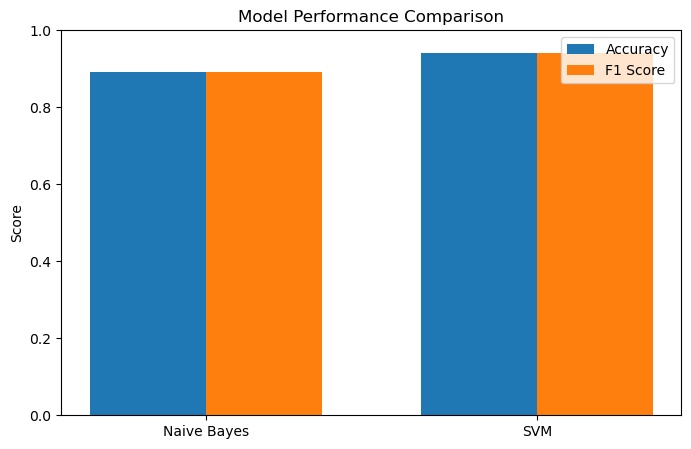

In [36]:
plt.figure(figsize=(8, 5))

x = np.arange(len(comparison))
width = 0.35

plt.bar(x - width/2, comparison['Accuracy'], width, label='Accuracy')
plt.bar(x + width/2, comparison['F1 Score'], width, label='F1 Score')

plt.xticks(x, comparison['Model'])
plt.ylabel('Score')
plt.title('Model Performance Comparison')
plt.ylim(0, 1)
plt.legend()

plt.show()

## Preprocessing Explanation

The text data was preprocessed before training the models.

The following steps were performed:

-Lowercasing: All text was converted to lowercase so that words such as
   "Happy" and "happy" are treated as the same word.
-Text Cleaning: Punctuation and special characters were removed to
   reduce unnecessary information.
-Tokenization: Each comment was divided into individual words (tokens).

-Stopword Removal: Common English words such as "the", "is", "and",
   and "am" were removed because they usually provide less useful information
   for emotion classification.

These preprocessing steps help reduce noise and create cleaner text features,
which can improve the performance of machine learning models.

## Feature Extraction - TF-IDF

TF-IDF (Term Frequency-Inverse Document Frequency) was used to convert the
cleaned text into numerical features.

TF-IDF gives higher importance to words that are useful for distinguishing
between different text samples while reducing the importance of very common
words.

The training data was converted into 7,733 TF-IDF features. The same feature
space was then used to transform the test data.

TF-IDF is suitable for this task because machine learning models require
numerical input instead of raw text.

#Model Comparison

The two machine learning models were evaluated using Accuracy and weighted
F1-score.

| Model | Accuracy | F1 Score |
------------------------------
| Naive Bayes | 89.06% | 89.06% |
| SVM | 94.11% | 94.10% |

SVM achieved higher Accuracy and F1-score than Naive Bayes. Therefore, SVM
performed better on this emotion classification dataset.

      Why SVM is Suitable
-------------------------
SVM performed better than Naive Bayes on this dataset, achieving approximately
94% accuracy.

SVM is suitable for text classification because text data represented using
TF-IDF can contain a large number of features. In this project, the TF-IDF
representation contained 7,733 features.

Based on the evaluation results, SVM is the preferred model for classifying
the emotions in this dataset.

Conclusion
-----------
In this project, we classified emotions from text.
We cleaned the text, removed stopwords, and used TF-IDF to convert text into numbers.
We trained two models: Naive Bayes and SVM.
Naive Bayes got 89.06% accuracy, while SVM got 94.11% accuracy.
So, SVM performed better than Naive Bayes and is the better model for this dataset.